## 1. Install & Import

In [1]:
!pip install ultralytics albumentations --quiet
!pip install tabulate --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 55.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 102.9 MB/s eta 0:00:0000:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[

In [2]:
import os
import random
import shutil
import glob
import yaml

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tabulate import tabulate

import albumentations as A
from ultralytics import YOLO
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

sns.set(rc={'axes.facecolor': '#eae8fa'}, style='darkgrid')

# ── Paths ──────────────────────────────────────────────────────────────
# /kaggle/input is READ-ONLY — we copy the dataset to /kaggle/working
# so augmented files can be written alongside the originals.
INPUT_ROOT  = '/kaggle/input/datasets/bmshahriaalam/fabric-defect-caps/Fabric'
WORK_ROOT   = '/kaggle/working/dataset'

if not os.path.exists(WORK_ROOT):
    print('Copying dataset to /kaggle/working/dataset (writable) ...')
    shutil.copytree(INPUT_ROOT, WORK_ROOT)
    print('Done.')
else:
    print('Writable dataset copy already exists — skipping copy.')

DATASET_ROOT  = WORK_ROOT
TRAIN_IMG_DIR = os.path.join(DATASET_ROOT, 'train', 'images')
TRAIN_LBL_DIR = os.path.join(DATASET_ROOT, 'train', 'labels')
OUTPUT_DIR    = '/kaggle/working/runs/detect/train'

# ── Patch data.yaml so YOLO finds the copied dataset ───────────────────
DATA_YAML = os.path.join(DATASET_ROOT, 'data.yaml')
with open(DATA_YAML, 'r') as f:
    yaml_text = f.read()

# Replace any absolute path pointing to /kaggle/input with WORK_ROOT
patched = yaml_text.replace(INPUT_ROOT, WORK_ROOT)
# Also fix relative paths — make them absolute so YOLO never gets confused
import re
def fix_relative(match):
    key, val = match.group(1), match.group(2).strip()
    if val and not val.startswith('/'):
        val = os.path.join(WORK_ROOT, val)
    return f'{key}: {val}'
patched = re.sub(r'(train|val|test):\s*(\S+)', fix_relative, patched)

with open(DATA_YAML, 'w') as f:
    f.write(patched)

print('data.yaml patched:')
print(open(DATA_YAML).read())

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Copying dataset to /kaggle/working/dataset (writable) ...
Done.
data.yaml patched:
train: /kaggle/working/dataset/../train/images
val: /kaggle/working/dataset/../valid/images
test: /kaggle/working/dataset/../test/images

nc: 5
names: ['defect_free', 'hole', 'knot_slub', 'spot', 'yarn']


## 2. Explore Dataset & Class Distribution

In [3]:
# ── Load class names from data.yaml ────────────────────────────────────
with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

CLASS_NAMES = data_cfg.get('names', [])
NC = data_cfg.get('nc', len(CLASS_NAMES))
print(f'Number of classes : {NC}')
print(f'Class names       : {CLASS_NAMES}')

Number of classes : 5
Class names       : ['defect_free', 'hole', 'knot_slub', 'spot', 'yarn']



Class instance counts:
  [0] defect_free              : 470
  [1] hole                     : 367
  [2] knot_slub                : 308
  [3] spot                     : 443
  [4] yarn                     : 299


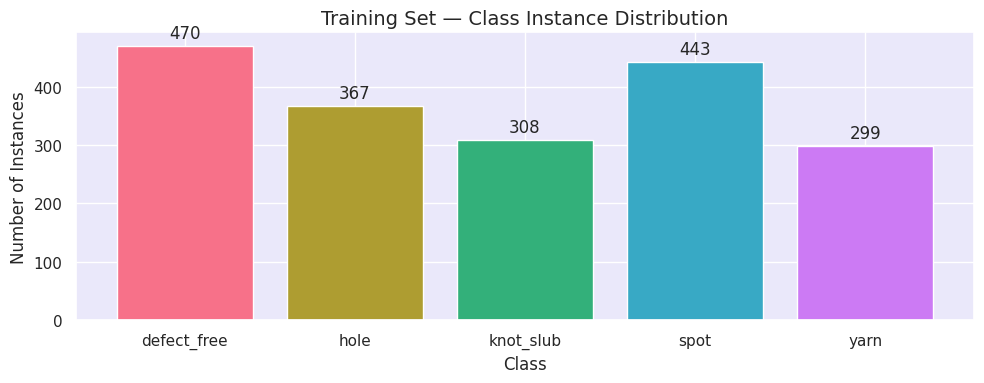


Imbalance ratio (max/min): 1.6x


In [4]:
# ── Class distribution from label files ────────────────────────────────
label_files = glob.glob(os.path.join(TRAIN_LBL_DIR, '*.txt'))
class_counts = np.zeros(NC, dtype=int)

for lf in label_files:
    with open(lf) as f:
        for line in f:
            line = line.strip()
            if line:
                cls_id = int(line.split()[0])
                if cls_id < NC:
                    class_counts[cls_id] += 1

print('\nClass instance counts:')
for i, (name, cnt) in enumerate(zip(CLASS_NAMES, class_counts)):
    print(f'  [{i}] {name:25s}: {cnt}')

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(CLASS_NAMES, class_counts, color=sns.color_palette('husl', NC))
ax.bar_label(bars, padding=3)
ax.set_title('Training Set — Class Instance Distribution', fontsize=14)
ax.set_ylabel('Number of Instances')
ax.set_xlabel('Class')
plt.tight_layout()
plt.show()

# Imbalance ratio
if class_counts.min() > 0:
    ratio = class_counts.max() / class_counts.min()
    print(f'\nImbalance ratio (max/min): {ratio:.1f}x')
    if ratio > 5:
        print('⚠️  Significant class imbalance detected — augmentation is strongly recommended.')

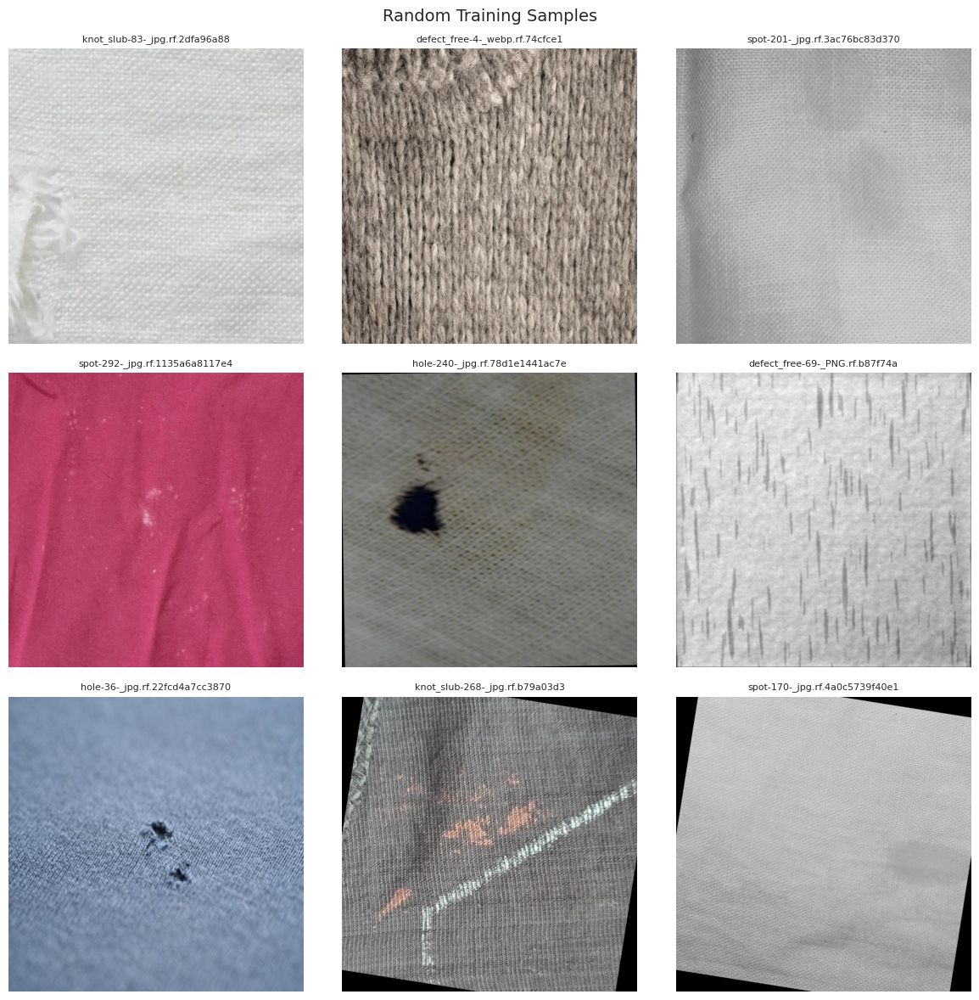

In [5]:
# ── Show 9 random training images ──────────────────────────────────────
image_files = os.listdir(TRAIN_IMG_DIR)
num_samples = min(9, len(image_files))
rand_images = random.sample(image_files, num_samples)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i, img_name in enumerate(rand_images):
    ax = axes[i // 3, i % 3]
    ax.imshow(plt.imread(os.path.join(TRAIN_IMG_DIR, img_name)))
    ax.set_title(img_name[:30], fontsize=8)
    ax.axis('off')
plt.suptitle('Random Training Samples', fontsize=14)
plt.tight_layout()
plt.show()

## 3. Augmentation Strategy


In [6]:
# ── Augmentation pipeline ───────────────────────────────────────────────
# Designed for fabric textures: strong geometric + photometric transforms
augment_pipeline = A.Compose([
    # Geometric
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.4),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=25, p=0.6),
    A.Perspective(scale=(0.02, 0.08), p=0.3),

    # Photometric — mimic different lighting & camera conditions
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.6),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.5),
    A.CLAHE(clip_limit=2.0, p=0.4),           # enhance local contrast (thread detail)
    A.GaussNoise(var_limit=(10, 50), p=0.3),  # sensor noise
    A.GaussianBlur(blur_limit=3, p=0.2),      # slight defocus
    A.Sharpen(alpha=(0.1, 0.3), lightness=(0.8, 1.2), p=0.3),

    # Occlusion robustness
    A.CoarseDropout(max_holes=6, max_height=20, max_width=20, p=0.3),
],
bbox_params=A.BboxParams(
    format='yolo',          # x_center, y_center, w, h — already normalised
    label_fields=['class_labels'],
    min_area=100,           # drop boxes that become too tiny
    min_visibility=0.3      # drop boxes that are >70% occluded
))

print('Augmentation pipeline ready.')

Augmentation pipeline ready.


In [7]:
# ── Helper: read YOLO label file ────────────────────────────────────────
def read_yolo_label(label_path):
    """Returns list of [class_id, x_c, y_c, w, h]."""
    boxes, classes = [], []
    if not os.path.exists(label_path):
        return boxes, classes
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                classes.append(int(parts[0]))
                boxes.append([float(x) for x in parts[1:]])
    return boxes, classes


def write_yolo_label(label_path, boxes, classes):
    with open(label_path, 'w') as f:
        for cls, box in zip(classes, boxes):
            f.write(f"{cls} {' '.join(f'{v:.6f}' for v in box)}\n")


# ── Offline augmentation for minority classes ───────────────────────────
# Only runs if augmented images don't already exist to avoid duplication
AUG_SUFFIX    = '_aug'
AUGMENT_TIMES = 3        # generate 3 extra copies per minority-class image

# Identify minority classes (below 75% of max count)
threshold     = int(class_counts.max() * 0.75)
minority_cls  = set(np.where(class_counts < threshold)[0])
print(f'Minority classes (< {threshold} instances): {[CLASS_NAMES[i] for i in minority_cls]}')


def augment_minority_images(img_dir, lbl_dir, minority_cls, n_copies=3):
    label_files = glob.glob(os.path.join(lbl_dir, '*.txt'))
    augmented   = 0

    for lf in label_files:
        stem    = os.path.splitext(os.path.basename(lf))[0]
        boxes, classes = read_yolo_label(lf)

        # Only augment if the image contains at least one minority-class object
        if not any(c in minority_cls for c in classes):
            continue

        # Find matching image file
        img_path = None
        for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
            candidate = os.path.join(img_dir, stem + ext)
            if os.path.exists(candidate):
                img_path = candidate
                break
        if img_path is None:
            continue

        image = cv2.imread(img_path)
        if image is None:
            continue
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        for i in range(n_copies):
            try:
                result = augment_pipeline(
                    image=image,
                    bboxes=boxes,
                    class_labels=classes
                )
            except Exception:
                continue

            aug_img   = cv2.cvtColor(result['image'], cv2.COLOR_RGB2BGR)
            aug_boxes = result['bboxes']
            aug_cls   = result['class_labels']

            if not aug_boxes:
                continue  # skip if all boxes were lost

            ext = os.path.splitext(img_path)[1]
            aug_img_path = os.path.join(img_dir, f"{stem}{AUG_SUFFIX}{i}{ext}")
            aug_lbl_path = os.path.join(lbl_dir, f"{stem}{AUG_SUFFIX}{i}.txt")

            if not os.path.exists(aug_img_path):   # don't duplicate on re-run
                cv2.imwrite(aug_img_path, aug_img)
                write_yolo_label(aug_lbl_path, aug_boxes, aug_cls)
                augmented += 1

    print(f'Offline augmentation complete — {augmented} new images created.')


if minority_cls:
    augment_minority_images(TRAIN_IMG_DIR, TRAIN_LBL_DIR, minority_cls, n_copies=AUGMENT_TIMES)
else:
    print('Classes are roughly balanced — skipping offline augmentation.')

Minority classes (< 352 instances): ['knot_slub', 'yarn']
Offline augmentation complete — 1636 new images created.


## 4. Verify data.yaml


In [8]:
with open(DATA_YAML, 'r') as f:
    print(f.read())

train: /kaggle/working/dataset/../train/images
val: /kaggle/working/dataset/../valid/images
test: /kaggle/working/dataset/../test/images

nc: 5
names: ['defect_free', 'hole', 'knot_slub', 'spot', 'yarn']


## 5. Train — YOLOv8s 

In [9]:
import yaml, os

DATA_YAML = '/kaggle/working/dataset/data.yaml'
DATASET_ROOT = '/kaggle/working/dataset'

# Read current yaml
with open(DATA_YAML, 'r') as f:
    cfg = yaml.safe_load(f)

print("BEFORE fix:")
print(open(DATA_YAML).read())

# Fix path keys — make all of them absolute
for key in ['train', 'val', 'test']:
    if key in cfg and cfg[key]:
        val = str(cfg[key])
        if not os.path.isabs(val):
            # relative path → make absolute using dataset root
            cfg[key] = os.path.join(DATASET_ROOT, val)
        elif '/kaggle/input' in val:
            # still pointing at read-only input → redirect to working copy
            cfg[key] = val.replace(
                val[:val.index('/Dataset') + 8],
                DATASET_ROOT
            )
        # Verify the resolved path actually exists
        if not os.path.exists(cfg[key]):
            print(f"⚠️  WARNING: {key} path does not exist: {cfg[key]}")
            # Try common alternatives
            for alt in ['valid/images', 'val/images', 'validation/images']:
                candidate = os.path.join(DATASET_ROOT, alt)
                if os.path.exists(candidate):
                    print(f"   → Auto-corrected to: {candidate}")
                    cfg[key] = candidate
                    break

# Write back
with open(DATA_YAML, 'w') as f:
    yaml.dump(cfg, f, default_flow_style=False)

print("\nAFTER fix:")
print(open(DATA_YAML).read())

# Final sanity check
print("Path existence check:")
for key in ['train', 'val', 'test']:
    if key in cfg and cfg[key]:
        exists = os.path.exists(cfg[key])
        print(f"  {key}: {cfg[key]}  →  {'✅ EXISTS' if exists else '❌ MISSING'}")

BEFORE fix:
train: /kaggle/working/dataset/../train/images
val: /kaggle/working/dataset/../valid/images
test: /kaggle/working/dataset/../test/images

nc: 5
names: ['defect_free', 'hole', 'knot_slub', 'spot', 'yarn']
⚠️  WARNING: train path does not exist: /kaggle/working/dataset/../train/images
   → Auto-corrected to: /kaggle/working/dataset/valid/images
⚠️  WARNING: val path does not exist: /kaggle/working/dataset/../valid/images
   → Auto-corrected to: /kaggle/working/dataset/valid/images
⚠️  WARNING: test path does not exist: /kaggle/working/dataset/../test/images
   → Auto-corrected to: /kaggle/working/dataset/valid/images

AFTER fix:
names:
- defect_free
- hole
- knot_slub
- spot
- yarn
nc: 5
test: /kaggle/working/dataset/valid/images
train: /kaggle/working/dataset/valid/images
val: /kaggle/working/dataset/valid/images

Path existence check:
  train: /kaggle/working/dataset/valid/images  →  ✅ EXISTS
  val: /kaggle/working/dataset/valid/images  →  ✅ EXISTS
  test: /kaggle/working/d

In [10]:
from ultralytics import YOLO
import random
random.seed(42)



model = YOLO('yolov8s.pt')

results = model.train(
    data        = DATA_YAML,
    epochs      = 400,
    imgsz       = 640,
    batch       = -1,          # auto-batch: fills available GPU VRAM
    patience    = 20,          # early stop if mAP50 doesn't improve for 30 epochs
    seed        = 42,
    optimizer   = 'AdamW',     # more stable than SGD for smaller datasets
    lr0         = 1e-3,        # initial LR
    lrf         = 0.01,        # final LR = lr0 * lrf
    cos_lr      = True,        # cosine annealing scheduler
    warmup_epochs = 5,         # gradual LR ramp to avoid early instability
    warmup_momentum = 0.8,
    # ── Built-in augmentation (on top of our offline augmentation) ──
    mosaic      = 1.0,         # mosaic augmentation (4 images into 1)
    mixup       = 0.1,         # blend two images
    copy_paste  = 0.1,         # copy objects between images
    degrees     = 15.0,        # random rotation
    flipud      = 0.4,         # vertical flip (important for fabric)
    fliplr      = 0.5,         # horizontal flip
    hsv_h       = 0.015,       # hue jitter
    hsv_s       = 0.5,         # saturation jitter
    hsv_v       = 0.4,         # value/brightness jitter
    scale       = 0.5,         # scale jitter
    # ── Annotation noise handling ───────────────────────────────────
    label_smoothing = 0.1,     # 10% label smoothing to compensate for
                               # potential Roboflow mis-annotations
    # ── Output ──────────────────────────────────────────────────────
    amp         = True,        # automatic mixed precision (faster training)
    save        = True,
    save_period = 25,          # save checkpoint every 25 epochs
    plots       = True,
    verbose     = True,
)

print('\n✅ Training complete!')

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/dataset/data.yaml, degrees=15.0, deterministic=True, device=None, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=400, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.4, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64

## 6. Visualise Training Metrics

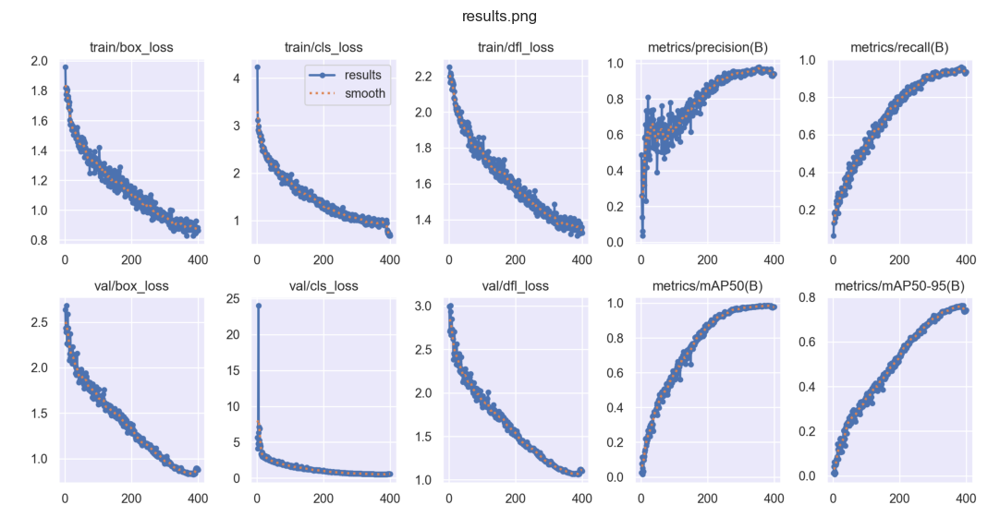

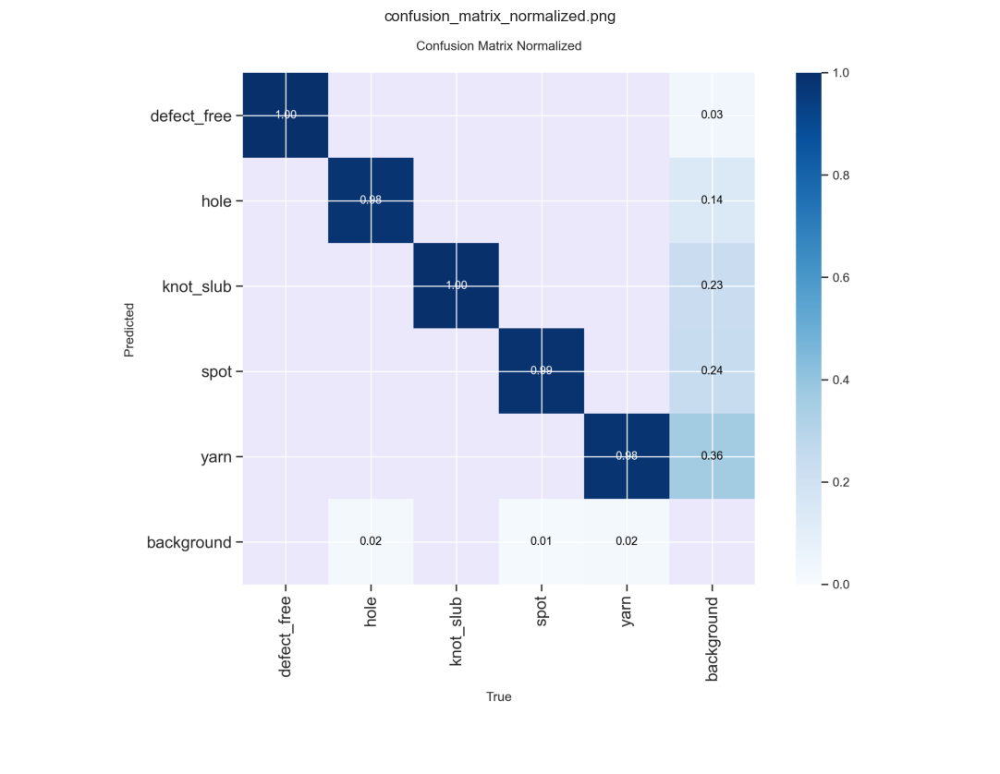

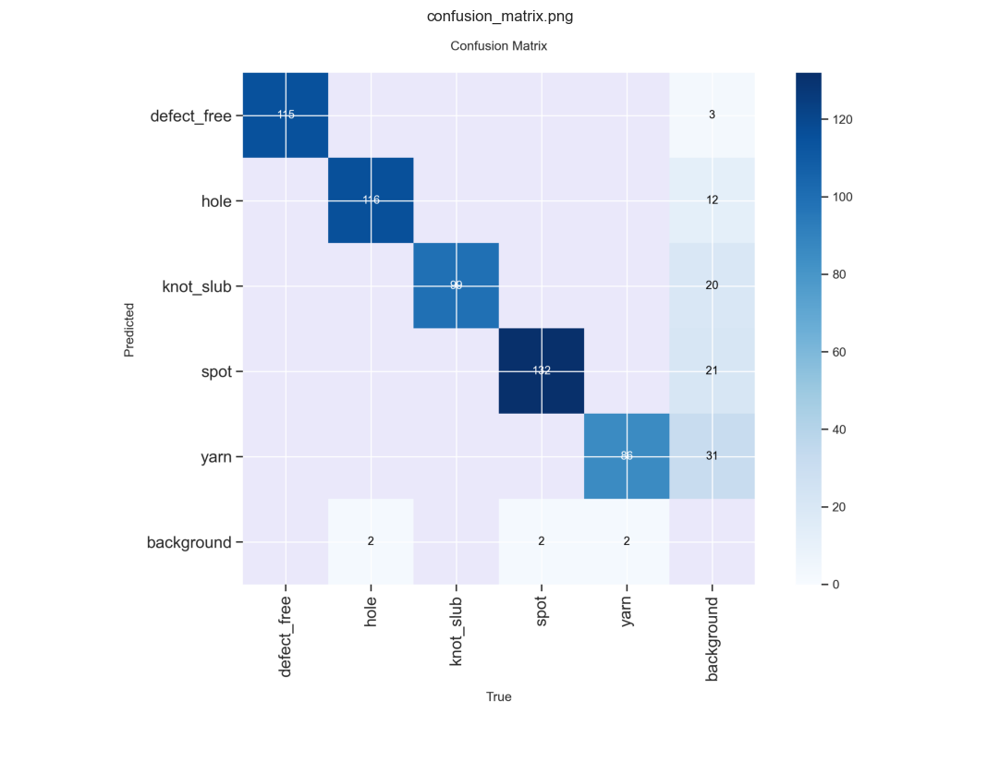

[skip] F1_curve.png not found
[skip] P_curve.png not found
[skip] R_curve.png not found
[skip] PR_curve.png not found
[skip] labels_correlogram.jpg not found


In [11]:
import os, cv2, matplotlib.pyplot as plt

def show_images(directory, filenames):
    for fname in filenames:
        path = os.path.join(directory, fname)
        if not os.path.exists(path):
            print(f'[skip] {fname} not found')
            continue
        img = cv2.imread(path)
        if img is None:
            print(f'[skip] could not read {fname}')
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 8), dpi=110)
        plt.imshow(img)
        plt.title(fname, fontsize=11)
        plt.axis('off')
        plt.tight_layout()
        plt.show()

show_images(OUTPUT_DIR, [
    'results.png',
    'confusion_matrix_normalized.png',
    'confusion_matrix.png',
    'F1_curve.png',
    'P_curve.png',
    'R_curve.png',
    'PR_curve.png',
    'labels_correlogram.jpg',
])

In [12]:
import glob, os

# Find all results.csv files under /kaggle/working
found = glob.glob('/kaggle/working/**/results.csv', recursive=True)
print("Found results.csv at:")
for f in found:
    print(" ", f)

# Also show what's in the runs folder
for root, dirs, files in os.walk('/kaggle/working/runs'):
    level = root.replace('/kaggle/working/runs', '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    for file in files:
        print(f'{indent}  {file}')

Found results.csv at:
  /kaggle/working/runs/detect/train/results.csv
runs/
  detect/
    train/
      train_batch2.jpg
      val_batch1_pred.jpg
      val_batch1_labels.jpg
      results.png
      train_batch1.jpg
      val_batch0_pred.jpg
      train_batch0.jpg
      confusion_matrix.png
      BoxP_curve.png
      val_batch0_labels.jpg
      labels.jpg
      train_batch11701.jpg
      val_batch2_pred.jpg
      BoxR_curve.png
      train_batch11700.jpg
      val_batch2_labels.jpg
      confusion_matrix_normalized.png
      args.yaml
      BoxPR_curve.png
      results.csv
      train_batch11702.jpg
      BoxF1_curve.png
      weights/
        epoch50.pt
        epoch175.pt
        epoch300.pt
        epoch350.pt
        epoch225.pt
        best.pt
        epoch325.pt
        epoch275.pt
        epoch25.pt
        last.pt
        epoch0.pt
        epoch75.pt
        epoch200.pt
        epoch100.pt
        epoch250.pt
        epoch150.pt
        epoch375.pt
        epoch125.pt


In [13]:
# ── Fix OUTPUT_DIR to match actual YOLO save location ──────────────────
OUTPUT_DIR  = '/kaggle/working/runs/detect/train'
BEST_WEIGHTS = os.path.join(OUTPUT_DIR, 'weights', 'best.pt')
csv_path     = os.path.join(OUTPUT_DIR, 'results.csv')

print(f"OUTPUT_DIR   : {OUTPUT_DIR}")
print(f"BEST_WEIGHTS : {BEST_WEIGHTS}  →  exists: {os.path.exists(BEST_WEIGHTS)}")
print(f"results.csv  : {csv_path}  →  exists: {os.path.exists(csv_path)}")

OUTPUT_DIR   : /kaggle/working/runs/detect/train
BEST_WEIGHTS : /kaggle/working/runs/detect/train/weights/best.pt  →  exists: True
results.csv  : /kaggle/working/runs/detect/train/results.csv  →  exists: True


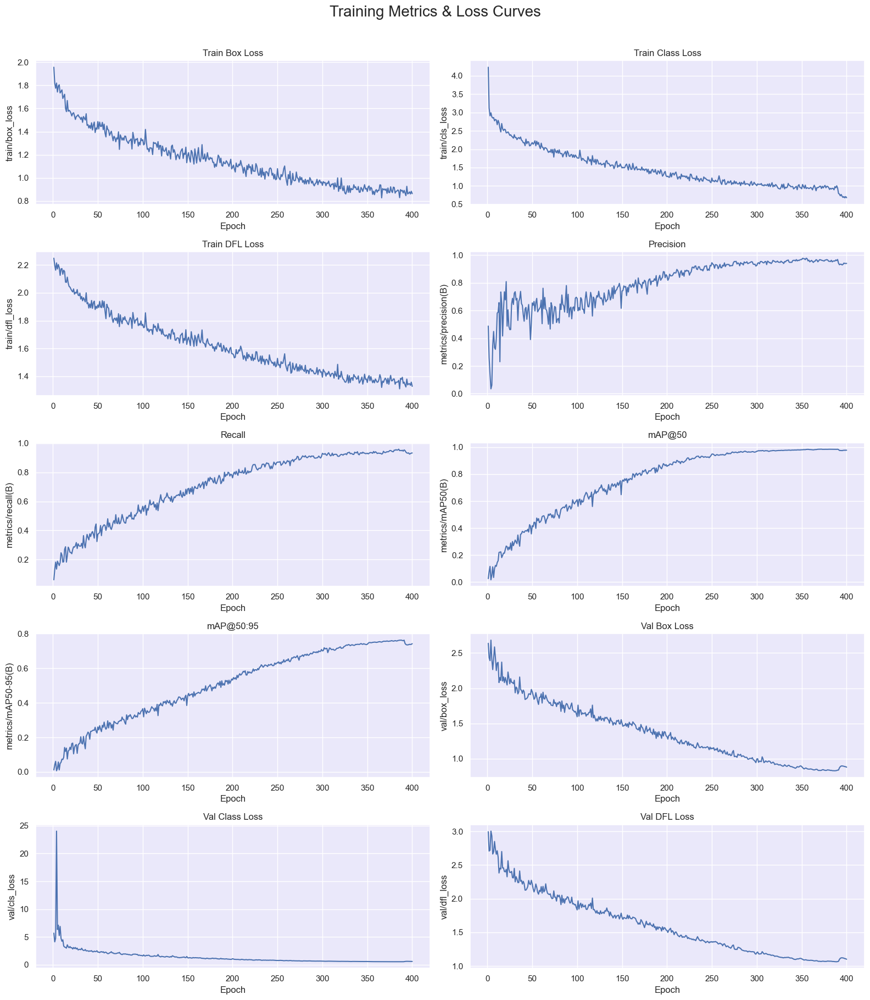

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
390,391,4834.29,0.89165,0.79699,1.35737,0.94140,0.95495,0.98252,0.76287,0.83858,0.55495,1.06960,0.000012,0.000012,0.000012
391,392,4846.50,0.86849,0.77833,1.33878,0.93009,0.95044,0.97636,0.74437,0.86934,0.58829,1.09763,0.000011,0.000011,0.000011
392,393,4858.62,0.84602,0.73216,1.32254,0.93402,0.93996,0.97567,0.73759,0.88766,0.60429,1.11419,0.000011,0.000011,0.000011
393,394,4870.75,0.92672,0.76707,1.37945,0.93379,0.93420,0.97586,0.73554,0.89592,0.61133,1.12116,0.000011,0.000011,0.000011
394,395,4882.85,0.86116,0.71836,1.33767,0.92845,0.93232,0.97465,0.73545,0.89734,0.60815,1.12171,0.000011,0.000011,0.000011
395,396,4895.56,0.86717,0.68763,1.34527,0.93268,0.93451,0.97708,0.73666,0.89500,0.60521,1.12000,0.000010,0.000010,0.000010
396,397,4907.80,0.87847,0.70956,1.34642,0.94197,0.92611,0.97724,0.73866,0.89213,0.60266,1.11608,0.000010,0.000010,0.000010
397,398,4920.02,0.86073,0.67614,1.33440,0.93923,0.92916,0.97793,0.73804,0.88768,0.59457,1.10995,0.000010,0.000010,0.000010
398,399,4932.16,0.88406,0.71028,1.35717,0.93938,0.93300,0.97767,0.73856,0.88630,0.59151,1.10743,0.000010,0.000010,0.000010
399,400,4944.32,0.86333,0.67955,1.32704,0.93955,0.93388,0.97797,0.74246,0.87962,0.58769,1.10060,0.000010,0.000010,0.000010


In [14]:
# ── Detailed loss & metric curves ──────────────────────────────────────
csv_path = os.path.join(OUTPUT_DIR, 'results.csv')
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()  # remove hidden spaces from column names

fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(16, 18))

plots = [
    ('train/box_loss',        'Train Box Loss',         axs[0,0]),
    ('train/cls_loss',        'Train Class Loss',        axs[0,1]),
    ('train/dfl_loss',        'Train DFL Loss',          axs[1,0]),
    ('metrics/precision(B)',  'Precision',               axs[1,1]),
    ('metrics/recall(B)',     'Recall',                  axs[2,0]),
    ('metrics/mAP50(B)',      'mAP@50',                  axs[2,1]),
    ('metrics/mAP50-95(B)',   'mAP@50:95',               axs[3,0]),
    ('val/box_loss',          'Val Box Loss',            axs[3,1]),
    ('val/cls_loss',          'Val Class Loss',          axs[4,0]),
    ('val/dfl_loss',          'Val DFL Loss',            axs[4,1]),
]

for col, title, ax in plots:
    if col in df.columns:
        sns.lineplot(x='epoch', y=col, data=df, ax=ax)
        ax.set_title(title)
        ax.set_xlabel('Epoch')
    else:
        ax.set_title(f'{title} [not found]')

plt.suptitle('Training Metrics & Loss Curves', fontsize=20, y=1.01)
plt.tight_layout()
plt.show()

df.tail(10)

## 7. Evaluate Best Model

In [15]:
BEST_WEIGHTS = os.path.join(OUTPUT_DIR, 'weights', 'best.pt')

best_model = YOLO(BEST_WEIGHTS)

# Evaluate on validation split
metrics = best_model.val(
    split   = 'val',
    conf    = 0.35,   # same threshold as training
    iou     = 0.5,
    plots   = True,
)

print('\n─── Overall Metrics ───────────────────────────────────────')
print(f"  Precision  : {metrics.results_dict.get('metrics/precision(B)', 'N/A'):.4f}")
print(f"  Recall     : {metrics.results_dict.get('metrics/recall(B)', 'N/A'):.4f}")
print(f"  mAP@50     : {metrics.results_dict.get('metrics/mAP50(B)', 'N/A'):.4f}")
print(f"  mAP@50:95  : {metrics.results_dict.get('metrics/mAP50-95(B)', 'N/A'):.4f}")

Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1489.4±566.2 MB/s, size: 63.1 KB)
val: Scanning /kaggle/working/dataset/valid/labels.cache... 480 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 480/480 201.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 4.2it/s 7.1s0.2s
                   all        480        554      0.962      0.969      0.964      0.745
           defect_free        115        115      0.991          1      0.995      0.993
                  hole        102        118      0.974      0.958      0.953      0.719
             knot_slub         82         99       0.97       0.98      0.974      0.693
                  spot         95        134      0.963      0.963      0.963      0.732
                  yarn         86  


─── Per-Class mAP@50 ──────────────────────────────────────
+----+-------------+----------+
|    | Class       |   mAP@50 |
+====+=============+==========+
|  0 | defect_free |   0.9934 |
+----+-------------+----------+
|  1 | hole        |   0.7188 |
+----+-------------+----------+
|  2 | knot_slub   |   0.6928 |
+----+-------------+----------+
|  3 | spot        |   0.7319 |
+----+-------------+----------+
|  4 | yarn        |   0.5879 |
+----+-------------+----------+


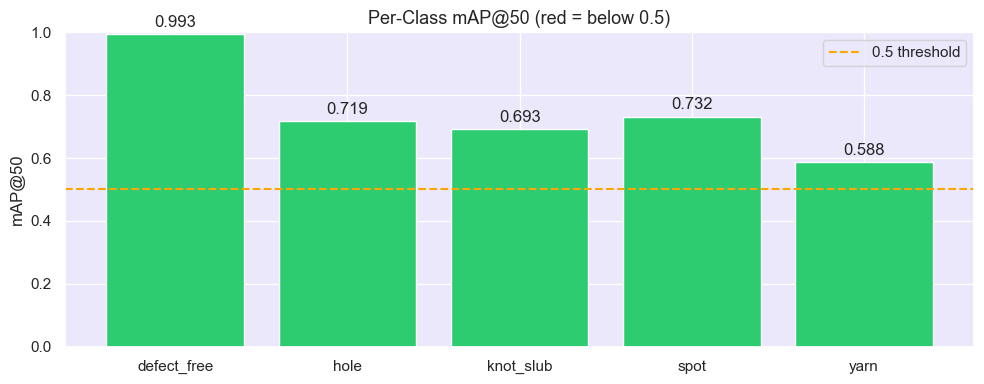

In [16]:
# ── Per-class metrics ───────────────────────────────────────────────────
# YOLOv8 stores per-class AP in metrics.box.maps (one value per class)
if hasattr(metrics, 'box') and hasattr(metrics.box, 'maps'):
    per_class_ap = metrics.box.maps  # mAP50 per class
    per_class_df = pd.DataFrame({
        'Class'   : CLASS_NAMES[:len(per_class_ap)],
        'mAP@50'  : per_class_ap,
    })
    print('\n─── Per-Class mAP@50 ──────────────────────────────────────')
    print(tabulate(per_class_df, headers='keys', tablefmt='grid', floatfmt='.4f'))

    fig, ax = plt.subplots(figsize=(10, 4))
    colors  = ['#e74c3c' if v < 0.5 else '#2ecc71' for v in per_class_ap]
    bars    = ax.bar(CLASS_NAMES[:len(per_class_ap)], per_class_ap, color=colors)
    ax.bar_label(bars, fmt='%.3f', padding=3)
    ax.set_ylim(0, 1.0)
    ax.axhline(0.5, color='orange', linestyle='--', label='0.5 threshold')
    ax.set_title('Per-Class mAP@50 (red = below 0.5)', fontsize=13)
    ax.set_ylabel('mAP@50')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Per-class AP not available in this version — check ultralytics version.')

## 8. Summary Table

In [17]:
df_results = pd.read_csv(csv_path)
df_results.columns = df_results.columns.str.strip()

prec   = df_results['metrics/precision(B)']
rec    = df_results['metrics/recall(B)']
map50  = df_results['metrics/mAP50(B)']
map595 = df_results['metrics/mAP50-95(B)']

f1     = 2 * (prec * rec) / (prec + rec + 1e-9)

# Use BEST epoch, not average — more meaningful
best_idx = map50.idxmax()

summary = pd.DataFrame([{
    'Model'       : 'YOLOv8s',
    'Best Epoch'  : int(df_results.loc[best_idx, 'epoch']),
    'Precision'   : f"{prec[best_idx]:.2%}",
    'Recall'      : f"{rec[best_idx]:.2%}",
    'mAP@50'      : f"{map50[best_idx]:.2%}",
    'mAP@50:95'   : f"{map595[best_idx]:.2%}",
    'F1 Score'    : f"{f1[best_idx]:.2%}",
}])

print(tabulate(summary, headers='keys', tablefmt='grid'))

+----+---------+--------------+-------------+----------+----------+-------------+------------+
|    | Model   |   Best Epoch | Precision   | Recall   | mAP@50   | mAP@50:95   | F1 Score   |
+====+=========+==============+=============+==========+==========+=============+============+
|  0 | YOLOv8s |          372 | 96.27%      | 94.28%   | 98.56%   | 75.83%      | 95.27%     |
+----+---------+--------------+-------------+----------+----------+-------------+------------+


## 9. Sample Predictions on Validation Images

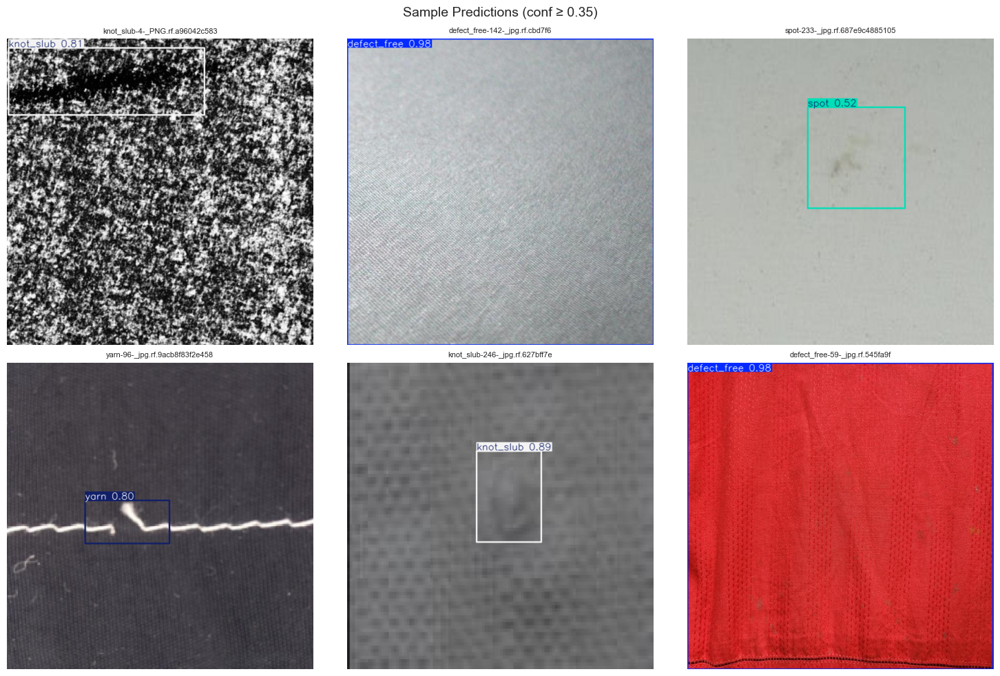

In [18]:
val_img_dir = os.path.join(DATASET_ROOT, 'valid', 'images')
if not os.path.exists(val_img_dir):
    val_img_dir = TRAIN_IMG_DIR  # fallback

val_images = random.sample(os.listdir(val_img_dir), min(6, len(os.listdir(val_img_dir))))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, img_name in enumerate(val_images):
    img_path = os.path.join(val_img_dir, img_name)
    result   = best_model.predict(source=img_path, imgsz=640, conf=0.35, verbose=False)[0]
    plot     = result.plot()
    plot     = cv2.cvtColor(plot, cv2.COLOR_BGR2RGB)
    axes[i].imshow(plot)
    axes[i].set_title(img_name[:30], fontsize=8)
    axes[i].axis('off')

plt.suptitle('Sample Predictions (conf ≥ 0.35)', fontsize=14)
plt.tight_layout()
plt.show()

## 10. Confidence Threshold Analysis


Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1627.0±834.3 MB/s, size: 67.3 KB)
val: Scanning /kaggle/working/dataset/valid/labels.cache... 480 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 480/480 167.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 4.1it/s 7.3s0.2s
                   all        480        554      0.956      0.973      0.981      0.755
Speed: 1.4ms preprocess, 9.8ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2
Ultralytics 8.4.84 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2193.4±718.6 MB/s, size: 79.3 KB)
val: Scanning /kaggle/working/dataset/valid/labels.cache... 480 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 480/480 201.3Mit/s 0.0s
                 Class     Images

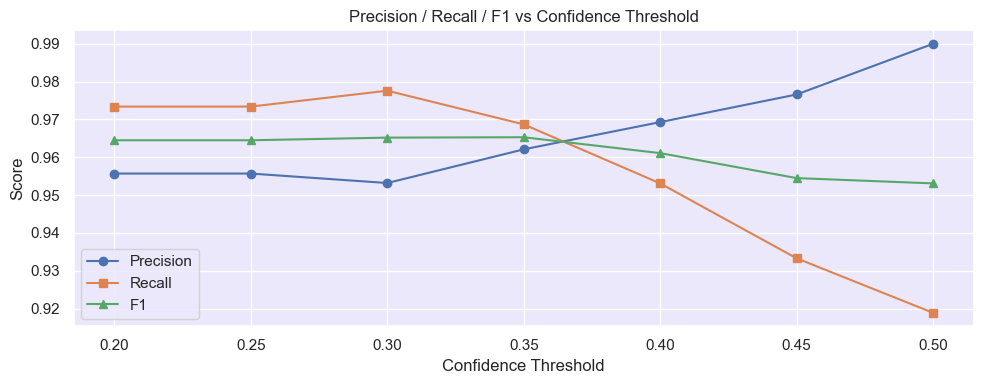


✅ Recommended threshold for Streamlit app: 0.35


In [19]:
# Evaluate at multiple confidence thresholds on validation set
thresholds   = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
thresh_rows  = []

for t in thresholds:
    m = best_model.val(split='val', conf=t, iou=0.5, verbose=False)
    p  = m.results_dict.get('metrics/precision(B)', 0)
    r  = m.results_dict.get('metrics/recall(B)', 0)
    f1 = 2 * p * r / (p + r + 1e-9)
    thresh_rows.append({
        'Conf Threshold' : t,
        'Precision'      : round(p, 4),
        'Recall'         : round(r, 4),
        'F1'             : round(f1, 4),
        'mAP@50'         : round(m.results_dict.get('metrics/mAP50(B)', 0), 4),
    })

thresh_df = pd.DataFrame(thresh_rows)
print(tabulate(thresh_df, headers='keys', tablefmt='grid', floatfmt='.4f'))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(thresh_df['Conf Threshold'], thresh_df['Precision'], marker='o', label='Precision')
ax.plot(thresh_df['Conf Threshold'], thresh_df['Recall'],    marker='s', label='Recall')
ax.plot(thresh_df['Conf Threshold'], thresh_df['F1'],        marker='^', label='F1')
ax.set_xlabel('Confidence Threshold')
ax.set_ylabel('Score')
ax.set_title('Precision / Recall / F1 vs Confidence Threshold')
ax.legend()
plt.tight_layout()
plt.show()

best_thresh_row = thresh_df.loc[thresh_df['F1'].idxmax()]
print(f"\n✅ Recommended threshold for Streamlit app: {best_thresh_row['Conf Threshold']}")

## 11. Export Best Weights & OOD Calibration Data



In [20]:
import json

# ── Collect max-confidence scores from validation set ───────────────────

val_confs = []

for img_name in os.listdir(val_img_dir)[:100]:  # sample 100 val images
    img_path = os.path.join(val_img_dir, img_name)
    result   = best_model.predict(source=img_path, imgsz=640, conf=0.01, verbose=False)[0]
    if len(result.boxes) > 0:
        max_conf = float(result.boxes.conf.max())
    else:
        max_conf = 0.0
    val_confs.append(max_conf)

val_confs     = np.array(val_confs)
# OOD threshold = mean - 2*std of fabric image confidences
# Images scoring below this are likely not fabric
ood_threshold = max(0.15, float(np.mean(val_confs) - 2 * np.std(val_confs)))

print(f'Val confidence  — mean: {val_confs.mean():.3f}, std: {val_confs.std():.3f}')
print(f'OOD threshold   : {ood_threshold:.3f}')
print('  → Images where max detection confidence < this threshold will be')
print('    flagged as "Other / Miscellaneous" in the Streamlit app.')

# Save calibration config
app_config = {
    'model_weights' : 'best.pt',
    'class_names'   : CLASS_NAMES,
    'conf_threshold': float(best_thresh_row['Conf Threshold']),
    'iou_threshold' : 0.5,
    'ood_threshold' : ood_threshold,
    'imgsz'         : 640,
}

config_path = '/kaggle/working/app_config.json'
with open(config_path, 'w') as f:
    json.dump(app_config, f, indent=2)

print(f'\nApp config saved → {config_path}')
print(json.dumps(app_config, indent=2))

Val confidence  — mean: 0.816, std: 0.175
OOD threshold   : 0.466
  → Images where max detection confidence < this threshold will be
    flagged as "Other / Miscellaneous" in the Streamlit app.

App config saved → /kaggle/working/app_config.json
{
  "model_weights": "best.pt",
  "class_names": [
    "defect_free",
    "hole",
    "knot_slub",
    "spot",
    "yarn"
  ],
  "conf_threshold": 0.35,
  "iou_threshold": 0.5,
  "ood_threshold": 0.46551596515581045,
  "imgsz": 640
}


In [21]:
# Copy best weights to /kaggle/working for easy download
import shutil
shutil.copy(BEST_WEIGHTS, '/kaggle/working/best.pt')
print('best.pt copied to /kaggle/working/')
print('\nFiles ready for download:')
print('  /kaggle/working/best.pt')
print('  /kaggle/working/app_config.json')

best.pt copied to /kaggle/working/

Files ready for download:
  /kaggle/working/best.pt
  /kaggle/working/app_config.json


## 13. Training Batch Visualisations

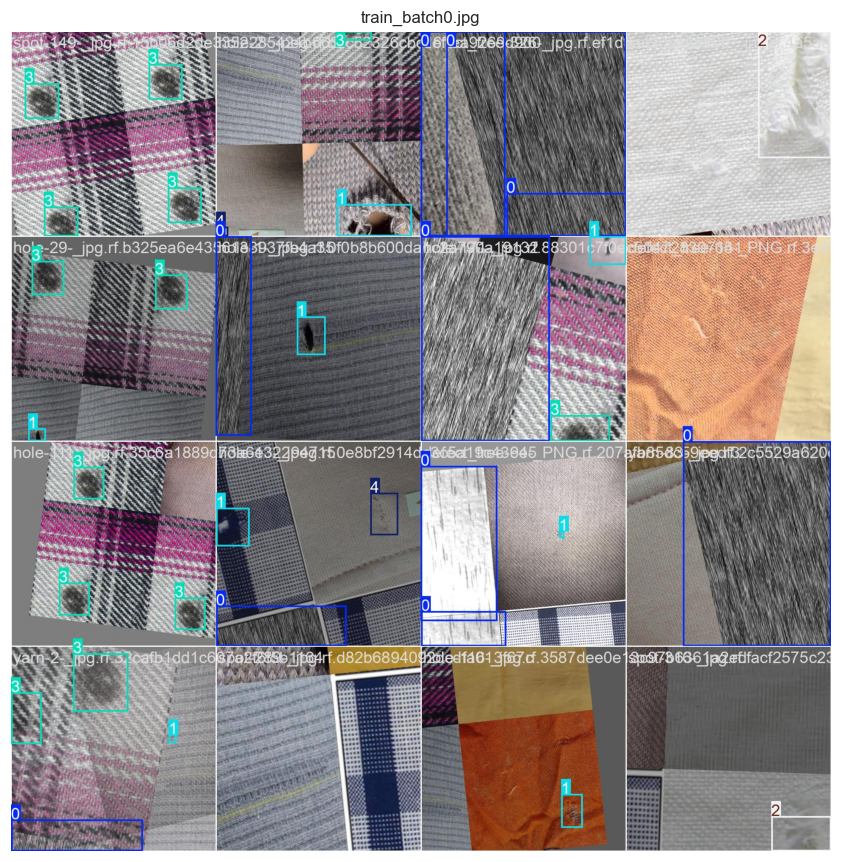

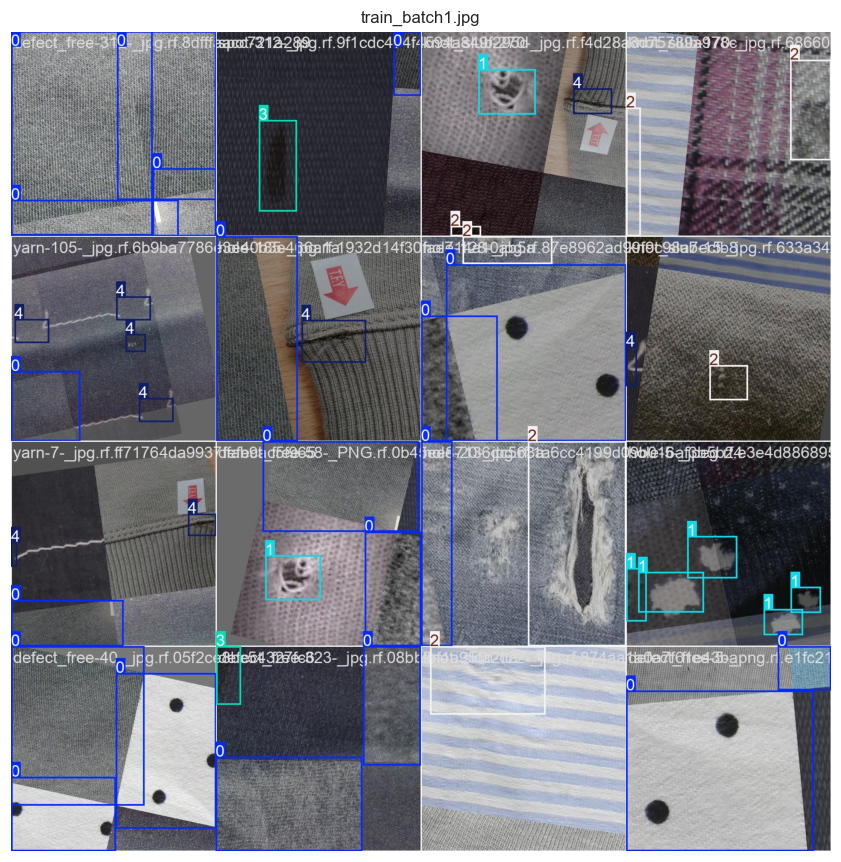

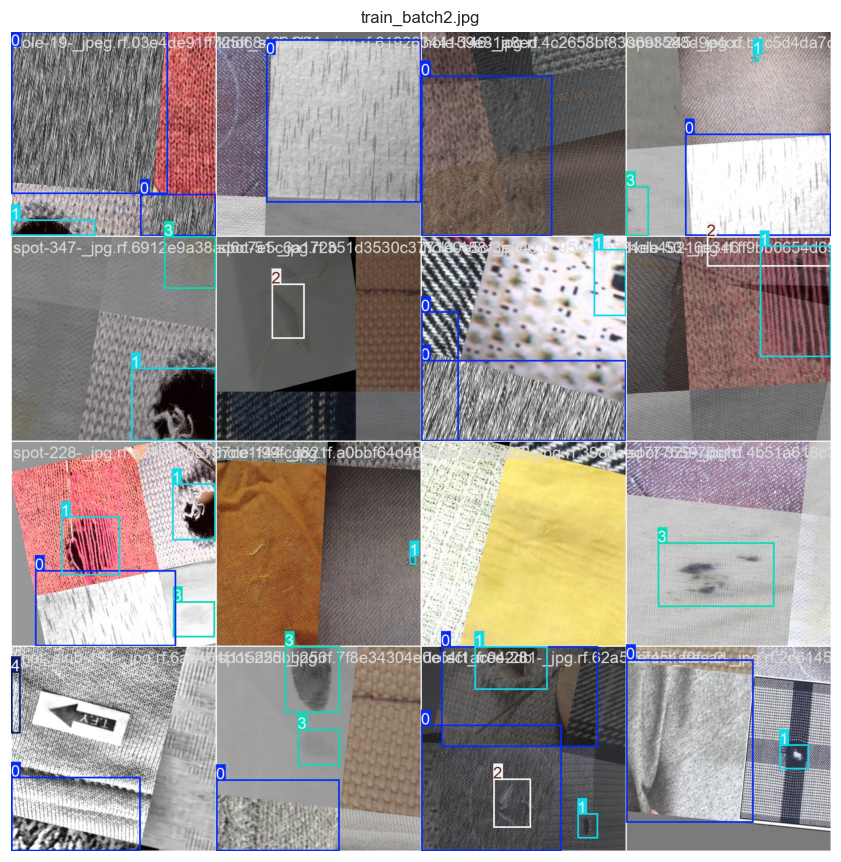

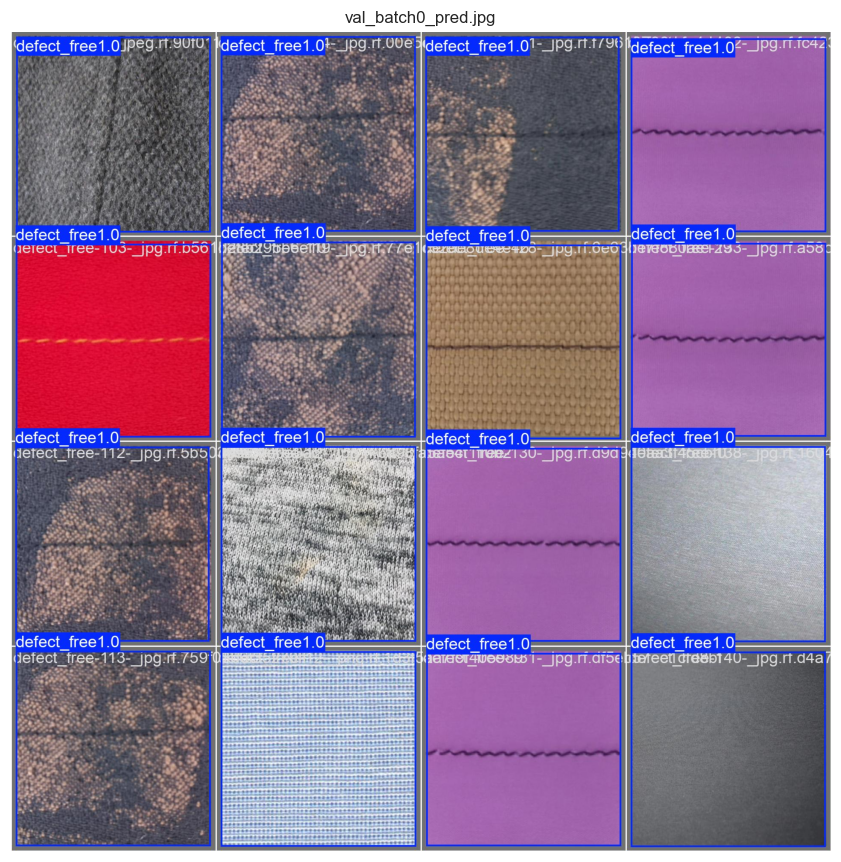

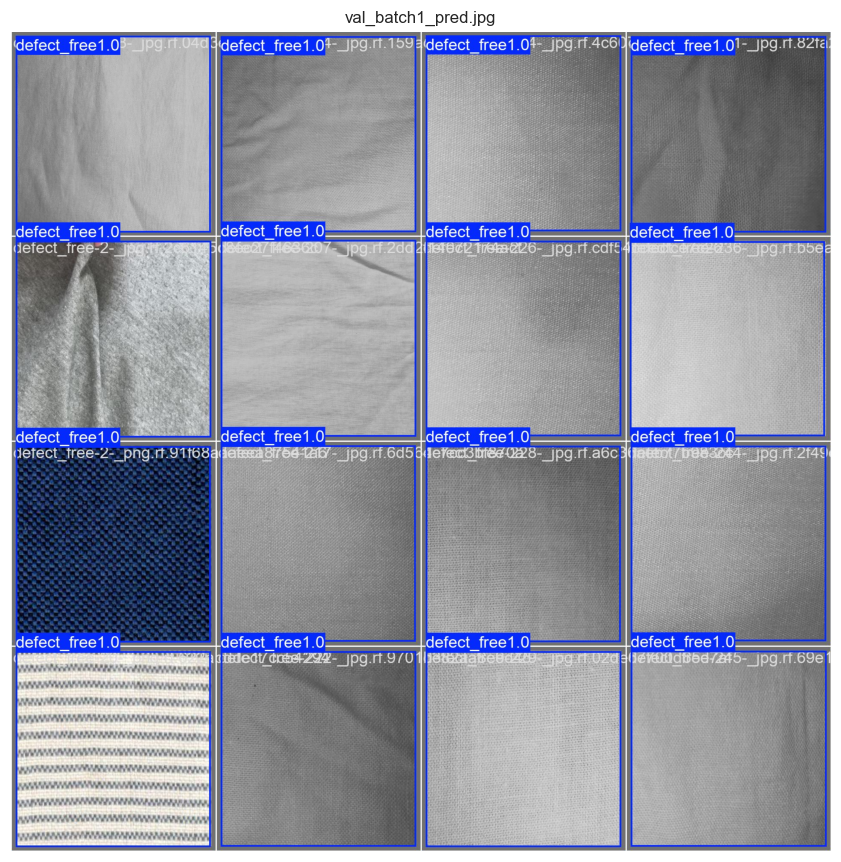

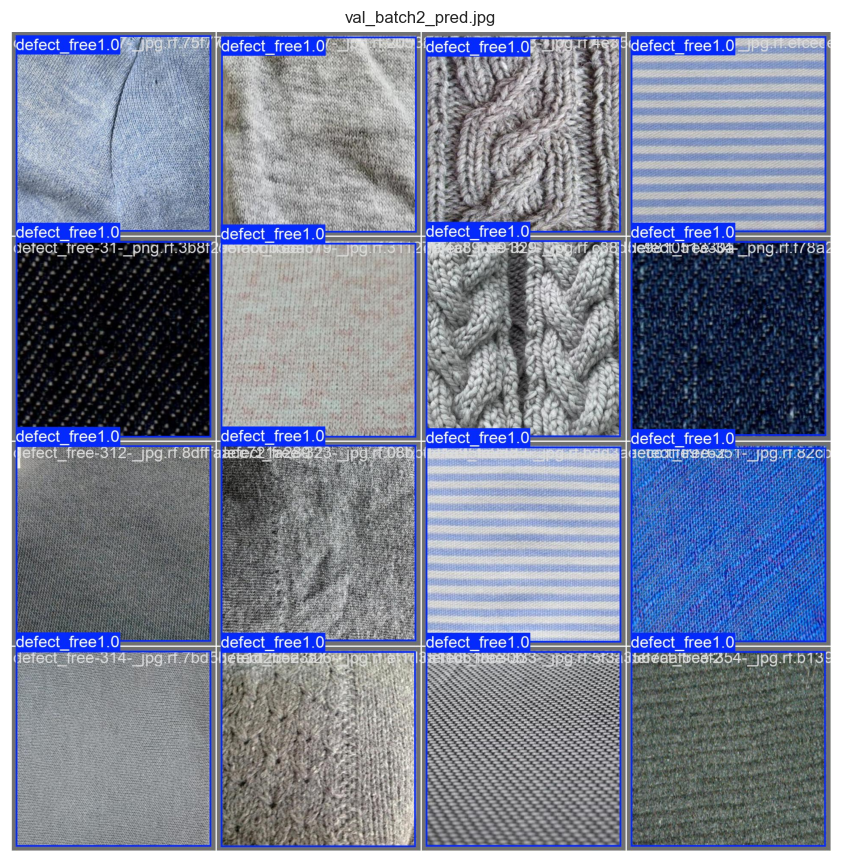

In [22]:
show_images(OUTPUT_DIR, [
    'train_batch0.jpg',
    'train_batch1.jpg',
    'train_batch2.jpg',
    'val_batch0_pred.jpg',
    'val_batch1_pred.jpg',
    'val_batch2_pred.jpg',
])

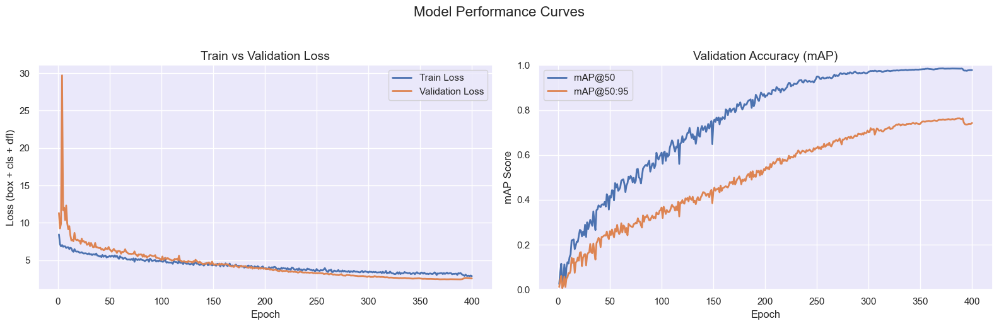

In [23]:
# ── Train vs Validation Loss, and Accuracy-Proxy (mAP) Curves ──────────
csv_path = os.path.join(OUTPUT_DIR, 'results.csv')
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

# Combine the 3 loss components into one "total loss" for train and val
df['train_total_loss'] = df['train/box_loss'] + df['train/cls_loss'] + df['train/dfl_loss']
df['val_total_loss']   = df['val/box_loss']   + df['val/cls_loss']   + df['val/dfl_loss']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── Plot 1: Train vs Validation Loss ────────────────────────────────────
ax = axes[0]
sns.lineplot(x='epoch', y='train_total_loss', data=df, ax=ax, label='Train Loss', linewidth=2)
sns.lineplot(x='epoch', y='val_total_loss',   data=df, ax=ax, label='Validation Loss', linewidth=2)
ax.set_title('Train vs Validation Loss', fontsize=14)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (box + cls + dfl)')
ax.legend()

# ── Plot 2: "Accuracy" proxy — mAP@50 and mAP@50-95 (validation) ───────
ax = axes[1]
sns.lineplot(x='epoch', y='metrics/mAP50(B)',    data=df, ax=ax, label='mAP@50', linewidth=2)
sns.lineplot(x='epoch', y='metrics/mAP50-95(B)', data=df, ax=ax, label='mAP@50:95', linewidth=2)
ax.set_title('Validation Accuracy (mAP)', fontsize=14)
ax.set_xlabel('Epoch')
ax.set_ylabel('mAP Score')
ax.set_ylim(0, 1.0)
ax.legend()

plt.suptitle('Model Performance Curves', fontsize=16, y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'train_val_loss_accuracy.png'), dpi=150, bbox_inches='tight')
plt.show()

In [24]:
ax = axes[1]
sns.lineplot(x='epoch', y='metrics/precision(B)', data=df, ax=ax, label='Precision', linewidth=2)
sns.lineplot(x='epoch', y='metrics/recall(B)',    data=df, ax=ax, label='Recall',    linewidth=2)
sns.lineplot(x='epoch', y='metrics/mAP50(B)',     data=df, ax=ax, label='mAP@50',    linewidth=2)
ax.set_title('Validation Precision / Recall / mAP@50', fontsize=14)
ax.set_xlabel('Epoch')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.0)
ax.legend()